# Test of pretrained VAE

In [2]:
import argparse
import os.path

import torch
from torch import nn,optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm
from dataset.dataset_loader import VideoDataset
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from torchvision.utils import save_image

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)
# The parser setting
parser = argparse.ArgumentParser()
parser = VideoDataset.add_model_specific_args(parser)
parser.add_argument('--data_path', type=str, default='dataset/2024-10-31_xacti_5fps')
# parser.add_argument('--data_path', type=str, default='/home/xu/xu/robo_nav/dataset/Huron_processed_seg')

parser.add_argument('--sequence_length', type=int, default=40)
parser.add_argument('--resolution', type=int, default=64)
parser.add_argument('--batch_size', type=int, default=8)
parser.add_argument('--num_workers', type=int, default=8)
parser.add_argument('--LR_RATE', type=int, default=1e-4)
parser.add_argument('--NUM_EPOCHS', type=int, default=100)
parser.add_argument('--iteration_num', type=int, default=1000)
args = parser.parse_args(args=[])

cuda


In [4]:
# Load the Dataset
Dataset = VideoDataset
dataset = Dataset(args.data_path, args.sequence_length,rgb=False, train=True, resolution=args.resolution)

# dataloader for the trainning
dataloader_train = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=True
)

# dataloader for the evaluation
dataset = Dataset(args.data_path, args.sequence_length,rgb=False, train=False, resolution=args.resolution)
dataloader_val = DataLoader(
    dataset,
    batch_size=args.batch_size,
    num_workers=args.num_workers,
    pin_memory=True,
    shuffle=False
)

metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl
metadata exists in: dataset/2024-10-31_xacti_5fps/test/metadata_40.pkl


metadata exists in: dataset/2024-10-31_xacti_5fps/train/metadata_40.pkl
809 dataset/2024-10-31_xacti_5fps/train/data_2024-10-30-16_52_32_6m_in_403_sec/15.mp4
li:0.210 ang:-0.200
li:0.266 ang:-0.300
li:0.266 ang:-0.200
li:0.259 ang:0.000
li:0.168 ang:0.300
li:0.231 ang:0.100
li:0.217 ang:0.000
li:0.238 ang:0.000
li:0.273 ang:0.000
li:0.315 ang:-0.100
li:0.287 ang:0.000
li:0.280 ang:0.100
li:0.252 ang:0.300
li:0.294 ang:0.200
li:0.259 ang:0.300
li:0.105 ang:0.200
li:0.021 ang:0.000
li:0.098 ang:0.000
li:0.007 ang:-0.100
li:0.056 ang:-0.300
li:0.189 ang:-0.300
li:0.231 ang:-0.300
li:0.308 ang:0.000
li:0.273 ang:-0.200
li:0.322 ang:-0.400
li:0.273 ang:-0.200
li:0.259 ang:0.000
li:0.280 ang:0.000
li:0.273 ang:-0.200
li:0.252 ang:-0.100
li:0.231 ang:-0.100
li:0.217 ang:0.000
tensor([0., 0., 0., 1., 0., 0., 0., 0., 0.], device='cuda:0')
torch.Size([40, 4, 8, 8])


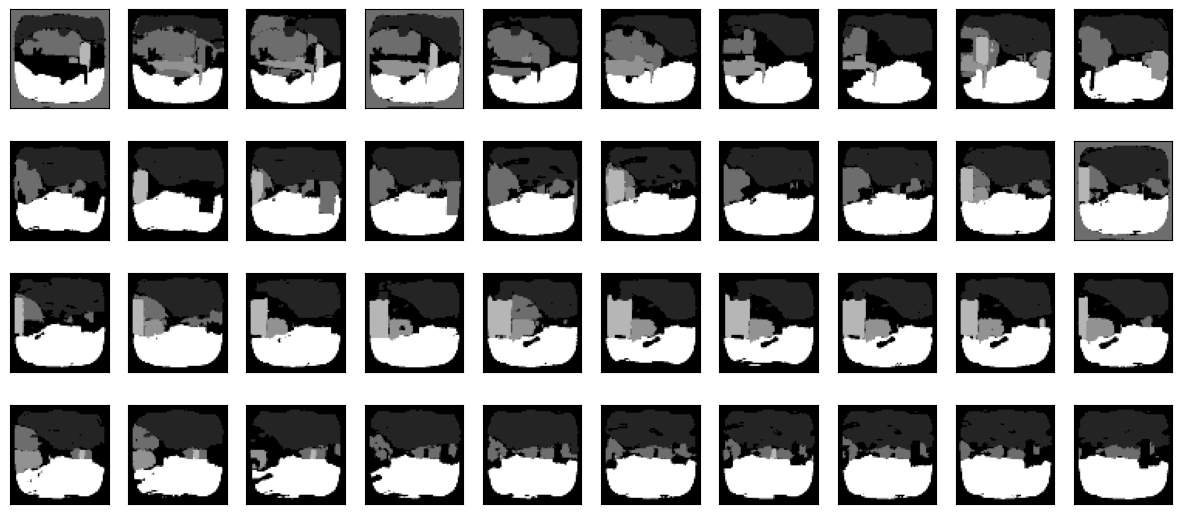

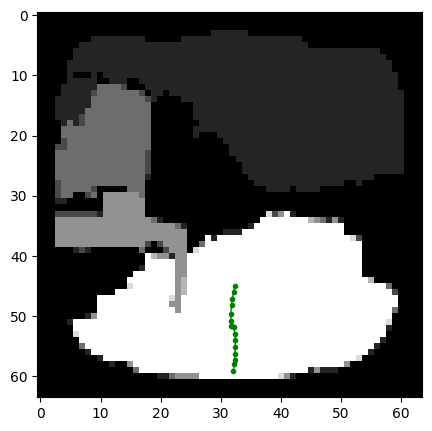

In [13]:
from utils import visual_vid_mmot
mulgpu = True

valid_dataset = Dataset(args.data_path, args.sequence_length,rgb=False, train=True, resolution=args.resolution)
batch, vid_idx, path = valid_dataset[15000]
print(vid_idx, path)

x, mot = dict.values(batch)
mot = mot.reshape(1,2,args.sequence_length).permute(0,2,1).to(DEVICE)
visual_vid_mmot(x.reshape(1,args.sequence_length,64,64,9),mot.reshape(1,args.sequence_length,2), grid=False)

from diffusers.models import AutoencoderKL
raw_x = x.permute(0,3,1,2).to(DEVICE)
print(raw_x.permute(0,2,3,1)[0,0,0])
vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)

modelData = 'checkpoints_vae_seg/vae_20241031_60.pth.tar'
checkpoint = torch.load(modelData)
if mulgpu == True:
    state_dict = checkpoint['model_state_dict']
    state_dict = {k.replace("module.", ""): v for k, v in state_dict.items()}
else:
    state_dict = checkpoint['model_state_dict']
vae.load_state_dict(state_dict)

vae.to(DEVICE)

with torch.no_grad():
    # Map input images to latent space + normalize latents:
    enc = vae.encode(raw_x).latent_dist.sample()
print(enc.shape)



torch.Size([40, 9, 64, 64])
[3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3]
tensor([-14.0564,  -5.7186,  -7.6120,  14.8975,  -4.4131,  -8.3362,  -6.9158,
         -2.3541, -11.4057], device='cuda:0', grad_fn=<SelectBackward0>)
li:0.210 ang:-0.200
li:0.266 ang:-0.300
li:0.266 ang:-0.200
li:0.259 ang:0.000
li:0.168 ang:0.300
li:0.231 ang:0.100
li:0.217 ang:0.000
li:0.238 ang:0.000
li:0.273 ang:0.000
li:0.315 ang:-0.100
li:0.287 ang:0.000
li:0.280 ang:0.100
li:0.252 ang:0.300
li:0.294 ang:0.200
li:0.259 ang:0.300
li:0.105 ang:0.200
li:0.021 ang:0.000
li:0.098 ang:0.000
li:0.007 ang:-0.100
li:0.056 ang:-0.300
li:0.189 ang:-0.300
li:0.231 ang:-0.300
li:0.308 ang:0.000
li:0.273 ang:-0.200
li:0.322 ang:-0.400
li:0.273 ang:-0.200
li:0.259 ang:0.000
li:0.280 ang:0.000
li:0.273 ang:-0.200
li:0.252 ang:-0.100
li:0.231 ang:-0.100
li:0.217 ang:0.000


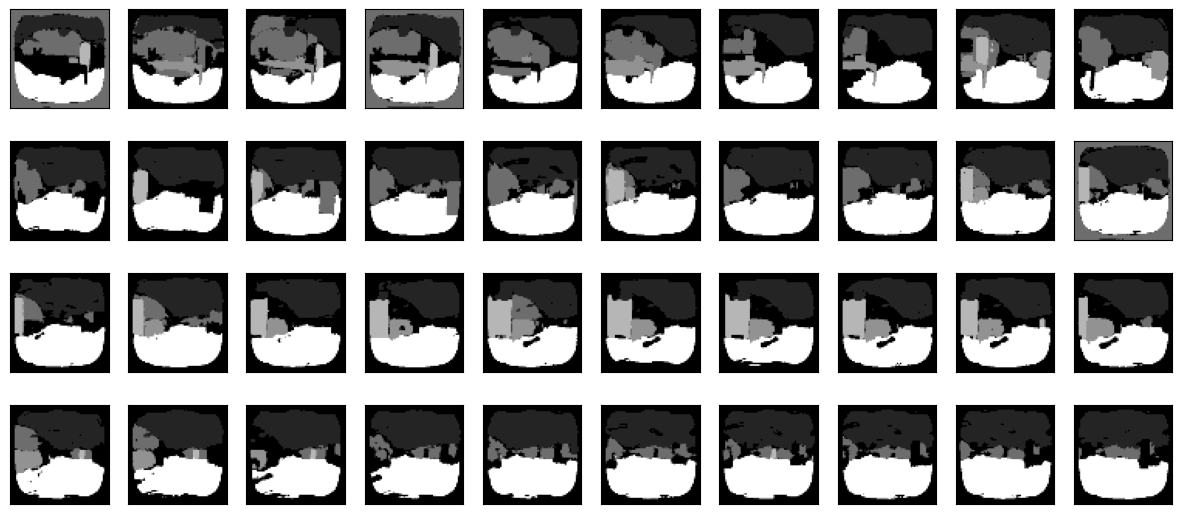

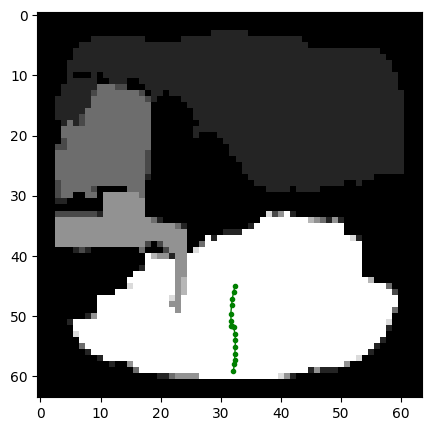

In [14]:
# z = torch.randn(16,4,8,8).to(DEVICE)

# enc[:,:,2:4,0:8] = 0
y = vae.decode(enc).sample
print(y.shape)
a = torch.argmax(y, 1).unsqueeze(1).cpu().numpy()
print(a[0,0,0])
y = y.permute(0,2,3,1)
print(y[0,0,0])
visual_vid_mmot(y.reshape(1,args.sequence_length,64,64,9),mot.reshape(1,args.sequence_length,2), grid=False)

In [ ]:
import math
import torch.nn.functional as F
def preprocess(video, resolution, rgb, sequence_length=None):
    # video: THWC, {0, ..., 255}
    video = video.permute(0, 3, 1, 2).float() / 255. # TCHW
    t, c, h, w = video.shape

    # temporal crop
    if sequence_length is not None:
        assert sequence_length <= t
        video = video[:sequence_length]
    # scale shorter side to resolution
    scale = resolution / min(h, w)
    if h < w:
        target_size = (resolution, math.ceil(w * scale))
    else:
        target_size = (math.ceil(h * scale), resolution)
    video = F.interpolate(video, size=target_size, mode='bilinear',
                          align_corners=False)

    # center crop
    t, c, h, w = video.shape
    w_start = (w - resolution) // 2
    h_start = (h - resolution) // 2
    video = video[:, :, h_start:h_start + resolution, w_start:w_start + resolution]
    video = video.permute(1, 0, 2, 3).contiguous() # CTHW
    if not rgb:
        video = video[0, :, :, :]
        # one hot encoding
        t,h,w = video.shape
        # print(video[0,10])
        flat_tensor = video.view(-1)
        class_tensor = torch.round(flat_tensor*10).to(torch.long)
        video_onehot = torch.nn.functional.one_hot(class_tensor,num_classes=9)
        video_onehot = video_onehot.reshape(t,h,w,9)
        video_onehot = video_onehot.to(torch.float)
    else:
        video_onehot = video.permute(1,2,3,0)

    return video_onehot

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse")
vae.encoder.conv_in = nn.Conv2d(9, vae.encoder.conv_in.out_channels, kernel_size=3, stride=1, padding=1)
vae.decoder.conv_out = nn.Conv2d(vae.decoder.conv_out.in_channels, 9, kernel_size=3, stride=1, padding=1)

modelData = '/home/xu/xu/robo_nav/checkpoints_vae_seg/vae_40.pth.tar'
checkpoint = torch.load(modelData)
vae.load_state_dict(checkpoint['model_state_dict'])
vae.to(DEVICE)

img = plt.imread('/home/xu/xu/robo_nav/test2.jpg')
img = preprocess(torch.tensor(img).reshape(1,64,64,1),resolution=64, rgb=False)
print(img.shape)

a = torch.argmax(img,3)
plt.imshow(a.squeeze().cpu().numpy(),'gray')

img = img.permute(0,3,1,2).to(DEVICE)
print(img.shape)
with torch.no_grad():
    # Map input images to latent space + normalize latents:
    enc = vae.encode(img).latent_dist.sample()
    y = vae.decode(enc).sample
    y = y.permute(0,2,3,1)
print(y.shape)
y = torch.argmax(y,3)
plt.imshow(y.squeeze().cpu().numpy(),'gray')
